# From univariate to multivariate distributions — and why regression appears

So far, we have mostly modeled one random variable at a time:

$$
X \sim p(x).
$$

For example, for a Gaussian random variable,

$$
X\sim \mathcal N(\mu,\sigma^2),
$$

we summarize the distribution using a mean and variance.

But real datasets usually measure several quantities on the **same observational unit**.

For one iris flower, we may measure

$$
\mathbf X
=
\begin{pmatrix}
\text{sepal length}\\
\text{sepal width}\\
\text{petal length}\\
\text{petal width}
\end{pmatrix}.
$$

For one penguin, we may measure

$$
\mathbf X
=
\begin{pmatrix}
\text{bill length}\\
\text{bill depth}\\
\text{flipper length}\\
\text{body mass}
\end{pmatrix}.
$$

The goal of this notebook is to move from

$$
p(x)
$$

to

$$
p(\mathbf x),
$$

and then ask why, if we want to **predict one variable from the others**, it may be useful to model a conditional relationship rather than the entire joint distribution.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.8)

## 1. Load the data

The notebook uses two standard teaching datasets:

- **Iris**: four measurements on each flower.
- **Palmer Penguins**: morphological measurements on individual penguins.

Both CSV files are included alongside this notebook.

In [2]:
iris = pd.read_csv("iris.csv")
penguins = pd.read_csv("palmer_penguins.csv")

display(iris.head())
display(penguins.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


# Part I — Iris: from one variable to a random vector

## 2. Start with one variable

Suppose we look only at petal length.

Then our data are

$$
X_1,\ldots,X_n,
$$

and we can study the marginal distribution

$$
p(x).
$$

We can estimate

$$
\mu = \mathbb E[X],
\qquad
\sigma^2=\operatorname{Var}(X).
$$

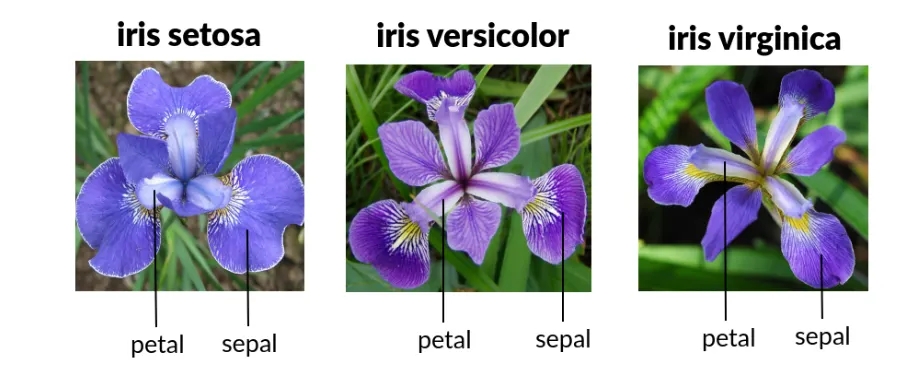

In [13]:
from PIL import Image
from IPython.display import display

img = Image.open("iris_flower.webp")
display(img)

Mean petal length = 3.758 cm
Variance          = 3.096 cm^2


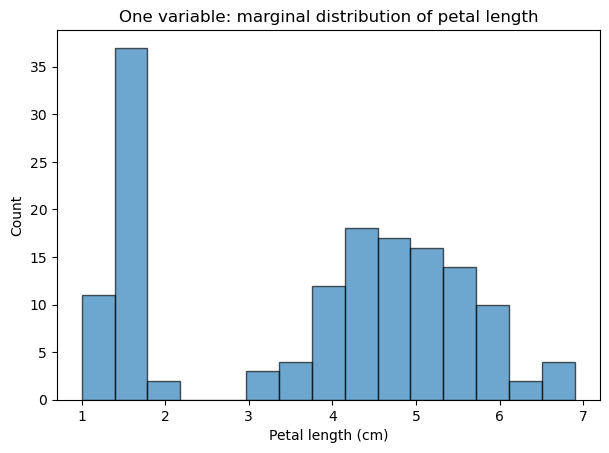

In [4]:
x = iris["petal_length_cm"].to_numpy()

print(f"Mean petal length = {x.mean():.3f} cm")
print(f"Variance          = {x.var(ddof=0):.3f} cm^2")

plt.hist(x, bins=15, edgecolor="black", alpha=0.65)
plt.xlabel("Petal length (cm)")
plt.ylabel("Count")
plt.title("One variable: marginal distribution of petal length")
plt.show()

### Question

What information is missing if we look only at petal length?

Each flower also has sepal length, sepal width, and petal width.

## 3. Two variables: the joint distribution

Now keep two measurements from each flower:

$$
\mathbf X
=
\begin{pmatrix}
X_1\\
X_2
\end{pmatrix}
=
\begin{pmatrix}
\text{petal length}\\
\text{petal width}
\end{pmatrix}.
$$

We are no longer describing one random quantity. We are describing a **random vector**.

The relevant object is now a joint distribution

$$
p(x_1,x_2).
$$

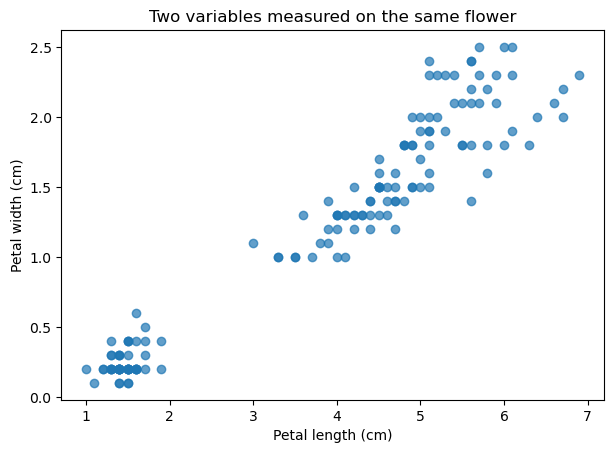

In [5]:
x1 = iris["petal_length_cm"].to_numpy()
x2 = iris["petal_width_cm"].to_numpy()

plt.scatter(x1, x2, alpha=0.7)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Two variables measured on the same flower")
plt.show()

The two measurements clearly do not vary independently.

For one random variable we used

$$
\mu=\mathbb E[X],
\qquad
\sigma^2=\operatorname{Var}(X).
$$

For a random vector we generalize these to a **mean vector**

$$
\boldsymbol\mu
=
\mathbb E[\mathbf X]
=
\begin{pmatrix}
\mathbb E[X_1]\\
\mathbb E[X_2]
\end{pmatrix},
$$

and a **covariance matrix**

$$
\Sigma
=
\begin{pmatrix}
\operatorname{Var}(X_1) & \operatorname{Cov}(X_1,X_2)\\
\operatorname{Cov}(X_1,X_2) & \operatorname{Var}(X_2)
\end{pmatrix}.
$$

In [6]:
iris_two = iris[["petal_length_cm", "petal_width_cm"]]

mu = iris_two.mean().to_numpy()
Sigma = np.cov(iris_two.to_numpy().T, ddof=0)

print("Mean vector:")
print(mu)

print("\nCovariance matrix:")
print(Sigma)

Mean vector:
[3.758      1.19933333]

Covariance matrix:
[[3.09550267 1.286972  ]
 [1.286972   0.57713289]]


### Interpretation

The diagonal entries of \(\Sigma\) are the ordinary variances.

The off-diagonal entry

$$
\operatorname{Cov}(X_1,X_2)
$$

measures whether deviations from the two means tend to occur together.

- positive covariance: large $X_1$ tends to occur with large $X_2$,
- negative covariance: large $X_1$ tends to occur with small $X_2$,
- covariance near zero: little linear co-variation.

### Question

Can the mean vector alone reveal the elongated shape of the cloud above?

No. The covariance is what captures the orientation and coupling of the variables.

## 4. Four variables: matrix notation becomes useful

Each flower has four measurements:

$$
\mathbf X=
\begin{pmatrix}
X_1\\X_2\\X_3\\X_4
\end{pmatrix}.
$$

Now

$$
\boldsymbol\mu\in\mathbb R^4,
\qquad
\Sigma\in\mathbb R^{4\times 4}.
$$

This is why matrix notation naturally appears in multivariate statistics.

In [7]:
iris_features = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm",
]

mu4 = iris[iris_features].mean()
Sigma4 = iris[iris_features].cov(ddof=0)

print("Mean vector:")
display(mu4)

print("Covariance matrix:")
display(Sigma4.round(3))

Mean vector:


sepal_length_cm    5.843333
sepal_width_cm     3.057333
petal_length_cm    3.758000
petal_width_cm     1.199333
dtype: float64

Covariance matrix:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,0.681,-0.042,1.266,0.513
sepal_width_cm,-0.042,0.189,-0.327,-0.121
petal_length_cm,1.266,-0.327,3.096,1.287
petal_width_cm,0.513,-0.121,1.287,0.577


## 5. Pairwise views of the same multivariate distribution

A four-dimensional distribution cannot be drawn directly, but we can inspect
two-dimensional marginals.

Notice that different pairs have very different dependence structures.

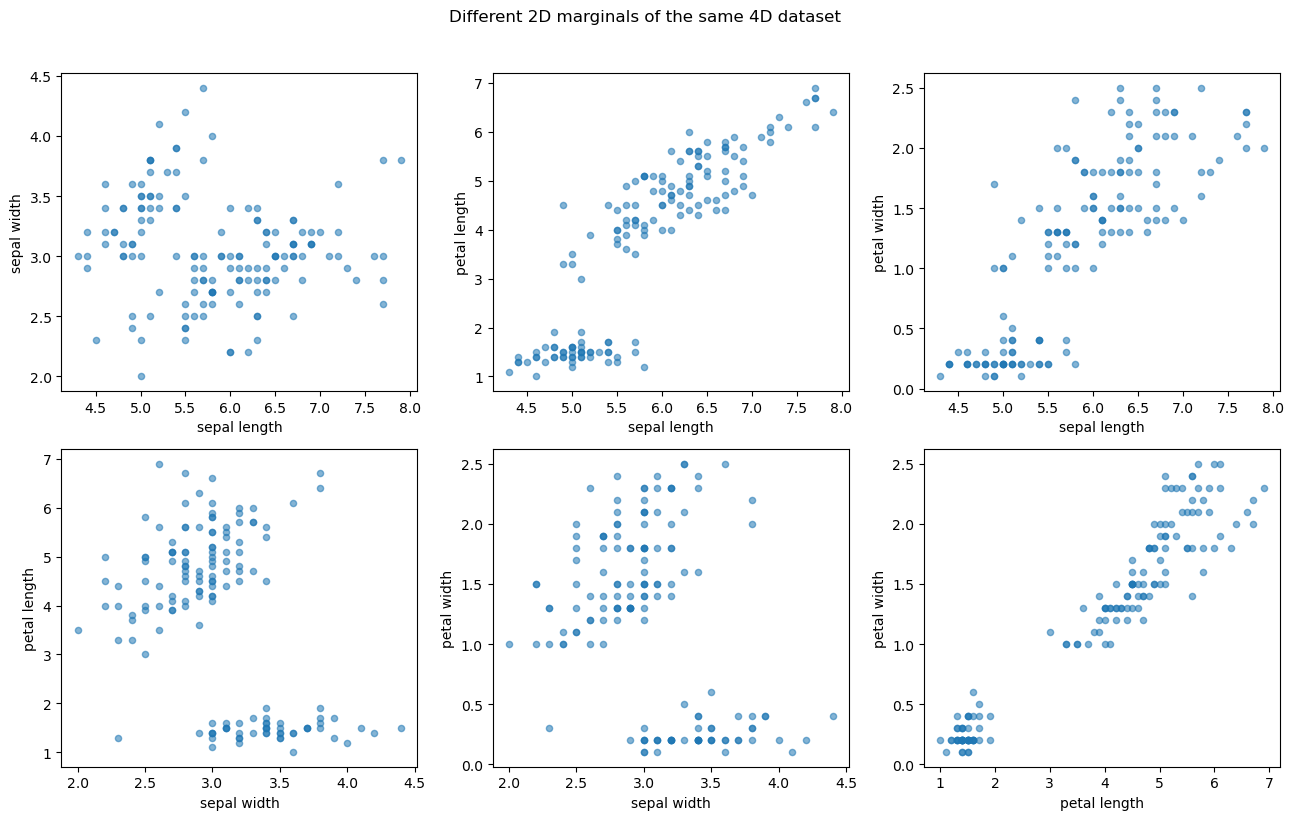

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

pairs = [
    ("sepal_length_cm", "sepal_width_cm"),
    ("sepal_length_cm", "petal_length_cm"),
    ("sepal_length_cm", "petal_width_cm"),
    ("sepal_width_cm", "petal_length_cm"),
    ("sepal_width_cm", "petal_width_cm"),
    ("petal_length_cm", "petal_width_cm"),
]

for ax, (a, b) in zip(axes.ravel(), pairs):
    ax.scatter(iris[a], iris[b], alpha=0.55, s=20)
    ax.set_xlabel(a.replace("_cm", "").replace("_", " "))
    ax.set_ylabel(b.replace("_cm", "").replace("_", " "))

plt.suptitle("Different 2D marginals of the same 4D dataset", y=1.02)
plt.tight_layout()
plt.show()

### Important observation

A multivariate distribution contains much more than a list of one-dimensional distributions.

Knowing

$$
p(X_1),\quad p(X_2),\quad p(X_3),\quad p(X_4)
$$

does **not** tell us how the variables move together.

That information lives in the joint distribution

$$
p(X_1,X_2,X_3,X_4).
$$

## 6. A useful warning: mean and covariance are not the full distribution

Color the same Iris measurements by species.

![Iris flower](iris_flower.webp)

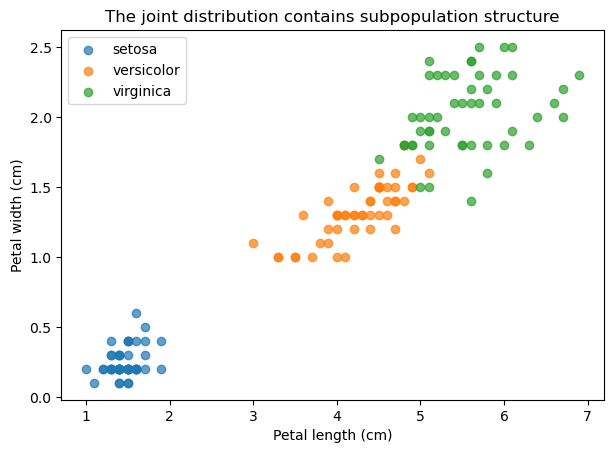

In [14]:
species_names = iris["species"].unique()

for species in species_names:
    d = iris[iris["species"] == species]
    plt.scatter(
        d["petal_length_cm"],
        d["petal_width_cm"],
        alpha=0.7,
        label=species
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("The joint distribution contains subpopulation structure")
plt.legend()
plt.show()

The cloud contains distinct biological subpopulations.

This is an important lesson:

$$
\boxed{\text{mean vector + covariance matrix do not fully specify an arbitrary multivariate distribution.}}
$$

They completely characterize a multivariate Gaussian, but a general joint distribution may have
clusters, skewness, nonlinear dependence, heavy tails, and other structure.

# Part II — Palmer Penguins: from a joint distribution to prediction

## 7. A penguin is also a random vector

We focus on four numerical measurements:

$$
\mathbf X=
\begin{pmatrix}
\text{bill length}\\
\text{bill depth}\\
\text{flipper length}\\
\text{body mass}
\end{pmatrix}.
$$

In [15]:
penguin_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]

peng = penguins.dropna(subset=penguin_features).copy()

print(f"Complete observations: {len(peng)}")
display(peng[penguin_features].describe().T)

Complete observations: 342


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


In [16]:
print("Mean vector:")
display(peng[penguin_features].mean())

print("Covariance matrix:")
display(peng[penguin_features].cov(ddof=0).round(2))

Mean vector:


bill_length_mm         43.921930
bill_depth_mm          17.151170
flipper_length_mm     200.915205
body_mass_g          4201.754386
dtype: float64

Covariance matrix:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,29.72,-2.53,50.23,2597.97
bill_depth_mm,-2.53,3.89,-16.17,-745.18
flipper_length_mm,50.23,-16.17,197.15,9795.69
body_mass_g,2597.97,-745.18,9795.69,641250.58


## 8. Visualize pairwise dependence

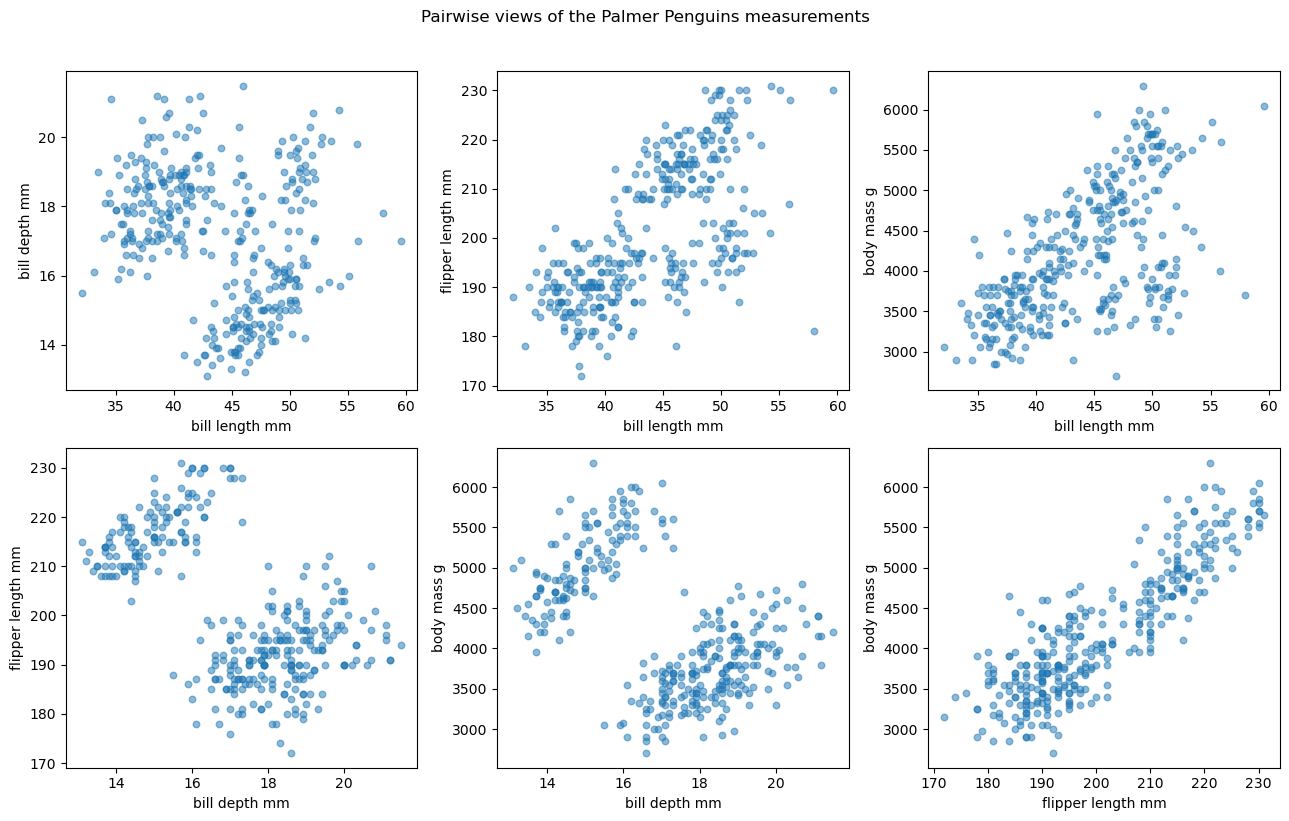

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

pairs = [
    ("bill_length_mm", "bill_depth_mm"),
    ("bill_length_mm", "flipper_length_mm"),
    ("bill_length_mm", "body_mass_g"),
    ("bill_depth_mm", "flipper_length_mm"),
    ("bill_depth_mm", "body_mass_g"),
    ("flipper_length_mm", "body_mass_g"),
]

for ax, (a, b) in zip(axes.ravel(), pairs):
    ax.scatter(peng[a], peng[b], alpha=0.5, s=22)
    ax.set_xlabel(a.replace("_", " "))
    ax.set_ylabel(b.replace("_", " "))

plt.suptitle("Pairwise views of the Palmer Penguins measurements", y=1.02)
plt.tight_layout()
plt.show()

### Questions

1. Which pairs show strong positive association?
2. Which pairs appear weakly related?
3. Is a covariance matrix enough to reveal all the visible structure?
4. What might explain the presence of multiple clouds?

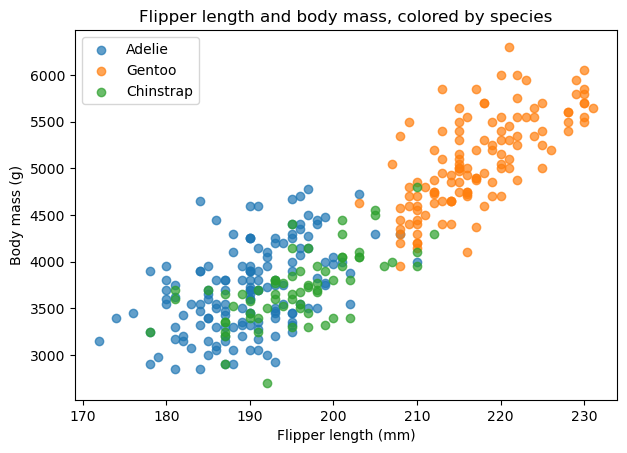

In [18]:
for species in peng["species"].dropna().unique():
    d = peng[peng["species"] == species]
    plt.scatter(
        d["flipper_length_mm"],
        d["body_mass_g"],
        alpha=0.7,
        label=species
    )

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper length and body mass, colored by species")
plt.legend()
plt.show()

## 9. Now change the scientific question

So far our goal has been descriptive:

$$
\boxed{\text{What is the joint distribution of all the measurements?}}
$$

That is a legitimate and often difficult problem:

$$
p(\text{bill length},\text{bill depth},\text{flipper length},\text{body mass}).
$$

But suppose our scientific question changes.

> We measure a penguin's flipper length. Can we predict its body mass?

Now we do **not necessarily need the entire joint distribution**.

The quantity we care about is the conditional behavior

$$
p(Y\mid X=x),
$$

where

$$
X=\text{flipper length},
\qquad
Y=\text{body mass}.
$$

For squared-error prediction, the ideal target is the conditional mean

$$
\boxed{
m(x)=\mathbb E[Y\mid X=x].
}
$$

## 10. What if we ignore \(X\)?

If we use only the univariate body-mass distribution, our best constant predictor is

$$
\hat y=\bar y.
$$

Every penguin receives exactly the same predicted body mass.

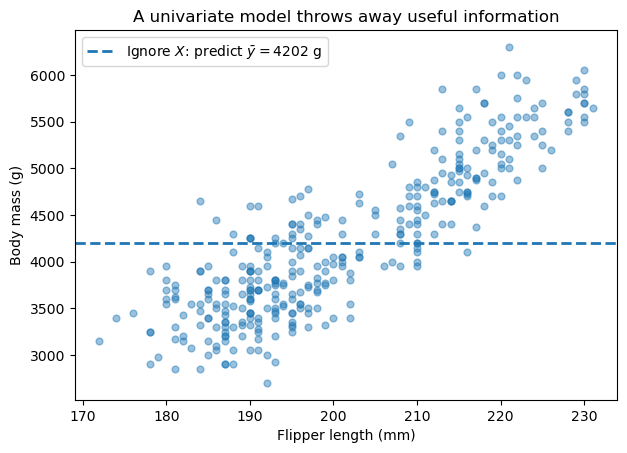

In [19]:
x = peng["flipper_length_mm"].to_numpy()
y = peng["body_mass_g"].to_numpy()

ybar = y.mean()

plt.scatter(x, y, alpha=0.45, s=24)
plt.axhline(ybar, linestyle="--", linewidth=2,
            label=rf"Ignore $X$: predict $\bar y={ybar:.0f}$ g")

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("A univariate model throws away useful information")
plt.legend()
plt.show()

### Question

Looking at this plot, does it make sense to predict exactly the same body mass for
a penguin with a 175 mm flipper and one with a 225 mm flipper?

The scatter around the overall mean is not purely unstructured noise.
Some of it is associated with the observed predictor \(X\).

## 11. Why not estimate the full joint density?

In principle, if we knew

$$
p(X,Y)
$$

perfectly, then we could obtain

$$
p(Y\mid X=x)
$$

and therefore

$$
\mathbb E[Y\mid X=x].
$$

So regression is **not more informative** than knowing the full joint distribution.

The issue is that learning a complete joint density can be a much harder problem than the
prediction task we actually care about.

Instead, we can model the conditional mean directly.

The simplest structured assumption is

$$
\boxed{
\mathbb E[Y\mid X=x]
=
w_0+w_1x.
}
$$

This is the beginning of linear regression.

## 12. Fit the simplest conditional model

Intercept w0 = -5780.83 g
Slope w1     = 49.69 g/mm


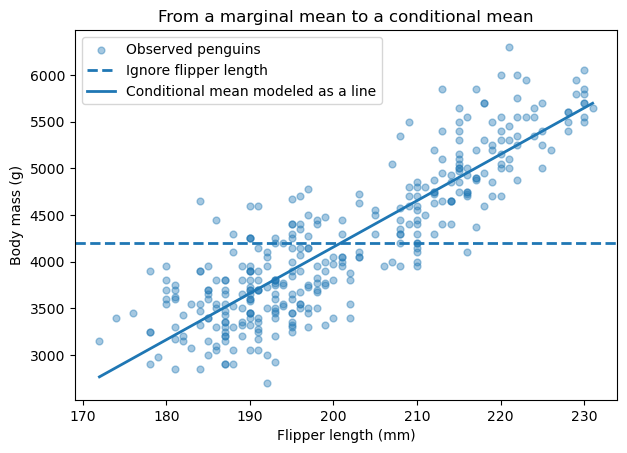

In [20]:
xbar = x.mean()
ybar = y.mean()

w1 = np.sum((x-xbar)*(y-ybar)) / np.sum((x-xbar)**2)
w0 = ybar - w1*xbar

xx = np.linspace(x.min(), x.max(), 200)
yy = w0 + w1*xx

print(f"Intercept w0 = {w0:.2f} g")
print(f"Slope w1     = {w1:.2f} g/mm")

plt.scatter(x, y, alpha=0.4, s=24, label="Observed penguins")
plt.axhline(ybar, linestyle="--", linewidth=2,
            label="Ignore flipper length")
plt.plot(xx, yy, linewidth=2,
         label="Conditional mean modeled as a line")

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("From a marginal mean to a conditional mean")
plt.legend()
plt.show()

The old model was

$$
\mathbb E[Y]=\mu.
$$

The new model is

$$
\boxed{
\mathbb E[Y\mid X=x]
=
w_0+w_1x.
}
$$

So regression is not a sudden new idea.

It is the next step:

$$
\boxed{
\text{Instead of estimating one mean for everyone,
let the mean depend on observed information.}
}
$$

## 13. Connection to moments

The fitted slope is

$$
\boxed{
\hat w_1
=
\frac{\widehat{\operatorname{Cov}}(X,Y)}
{\widehat{\operatorname{Var}}(X)}
}
$$

and

$$
\hat w_0
=
\bar y-\hat w_1\bar x.
$$

So covariance is not just a descriptive quantity: it directly enters the optimal
linear predictor.

In [21]:
cov_xy = np.mean((x-xbar)*(y-ybar))
var_x = np.mean((x-xbar)**2)

print(f"Cov(X,Y) = {cov_xy:.2f}")
print(f"Var(X)   = {var_x:.2f}")
print(f"Cov/Var  = {cov_xy/var_x:.2f}")
print(f"Slope    = {w1:.2f}")

Cov(X,Y) = 9795.69
Var(X)   = 197.15
Cov/Var  = 49.69
Slope    = 49.69


# Take-home progression

We began with one variable:

$$
X\sim p(x),
$$

with

$$
\mu=\mathbb E[X],
\qquad
\sigma^2=\operatorname{Var}(X).
$$

Then we moved to a random vector:

$$
\mathbf X=(X_1,\ldots,X_d)^\top,
$$

with

$$
\boldsymbol\mu=\mathbb E[\mathbf X],
\qquad
\Sigma=\operatorname{Cov}(\mathbf X).
$$

That led to the full joint distribution

$$
p(\mathbf x).
$$

Finally, when one variable became the quantity we wanted to predict, the relevant question changed from

$$
\boxed{\text{What is the entire joint distribution?}}
$$

to

$$
\boxed{\text{How does the distribution of }Y\text{ change when }X=x?}
$$

and, in particular,

$$
\boxed{
m(x)=\mathbb E[Y\mid X=x].
}
$$

The simplest structured approximation is

$$
\boxed{
m(x)=w_0+w_1x,
}
$$

which is linear regression.

### Questions to carry into the next lecture

1. How should we estimate \(w_0\) and \(w_1\) from data?
2. Why does minimizing squared error appear?
3. What probabilistic assumptions lead to least squares?
4. How uncertain are \(\hat w_0\) and \(\hat w_1\)?
5. How do confidence intervals, hypothesis tests, bootstrap, and Bayesian inference carry over?

Those are all questions for which we already have statistical machinery.